loading annotations into memory...
Done (t=0.35s)
creating index...
index created!
Total images listed in JSON: 8610
Mapping dataset directory structure...
Found 8610 image files on disk.


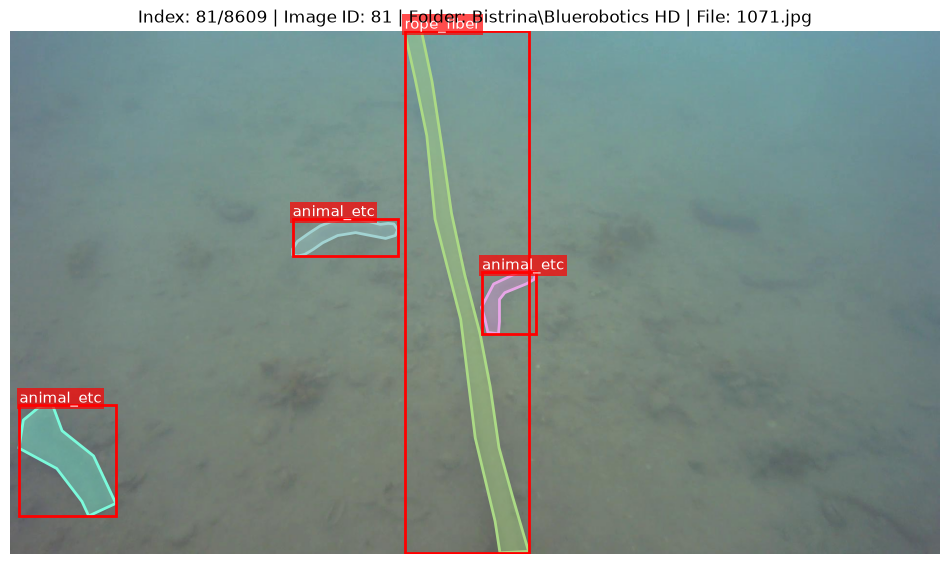

In [19]:
import os
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pycocotools.coco import COCO

# 1. Load COCO Annotations and Base Directory
ann_file = 'Seaclear Marine Debris Dataset/dataset.json'
base_dir = 'Seaclear Marine Debris Dataset'

coco = COCO(ann_file)
img_ids = coco.getImgIds()
cats = {cat['id']: cat['name'] for cat in coco.loadCats(coco.getCatIds())}

print(f"Total images listed in JSON: {len(img_ids)}")

# 2. Build a Lookup Dictionary for image filenames to full paths
print("Mapping dataset directory structure...")
file_path_map = {}
for root, _, files in os.walk(base_dir):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_path_map[f] = os.path.join(root, f)

print(f"Found {len(file_path_map)} image files on disk.")

# 3. Function to display any image by its Dataset Index
def show_image_by_index(index):
    if index < 0 or index >= len(img_ids):
        print(f"❌ Index {index} out of range! Valid range is 0 to {len(img_ids)-1}")
        return

    # Get Image Info
    img_id = img_ids[index]
    img_info = coco.loadImgs(img_id)[0]
    file_name = img_info['file_name']

    # Retrieve full path from lookup map
    image_path = file_path_map.get(file_name)

    if image_path is None or not os.path.exists(image_path):
        print(f"⚠️ Index {index}: File '{file_name}' not found on disk.")
        return

    # Load image
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1, figsize=(12, 10))
    ax.imshow(image)
    ax.axis('off')

    # Load & render annotations (Segmentation Mask + Bounding Box + Category Name)
    ann_ids = coco.getAnnIds(imgIds=img_id)
    anns = coco.loadAnns(ann_ids)

    # Render Segmentation Masks
    coco.showAnns(anns)

    # Render Bounding Boxes & Class Labels
    for ann in anns:
        bbox = ann['bbox']  # [x, y, width, height]
        x, y, w, h = bbox
        
        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
        
        cat_name = cats.get(ann['category_id'], 'Unknown')
        ax.text(x, y - 5, cat_name, color='white', fontsize=11, 
                bbox=dict(facecolor='red', alpha=0.7, pad=2, edgecolor='none'))

    # Subfolder relative path for title display
    rel_folder = os.path.relpath(os.path.dirname(image_path), base_dir)
    plt.title(f"Index: {index}/{len(img_ids)-1} | Image ID: {img_id} | Folder: {rel_folder} | File: {file_name}")
    plt.show()

# -------------------------------------------------------------
# 4. Usage: Change the index to inspect ANY image across any folder
# -------------------------------------------------------------
show_image_by_index(81)